---------------------------------------      EXCERCISE      ---------------------------------------
---------------------------------------------------------------------------------------------------------------------
We are tasked with designing the complete layout of a hexagonal cell, including all optical and electrical interconnections, within a die size of 2500×1500 μm
Design rules:
- Optical waveguides must NOT cross
- Electrical connections must NOT cross 
- Electrical/optical layers CAN cross 
- Optical I/O must be implemented using an array of grating couplers
- Each MZI must include two independently driven phase shifters, which may share a common ground
- Electrical pad array separation 150 μm
- Grating coupler array separation 127 μm

The deliverables are:
- GDS file
- Main document for creating the layout
- Dedicated PDK for the components

![My Image](Chip_scheme.PNG)

C:\Users\david\AppData\Roaming\Python\Python313\site-packages\cachetools\_cached.py:185: UserWarning: bend_euler angle should be 90 or 180. Got -90. Use bend_euler_all_angle instead.
  v = func(*args, **kwargs)


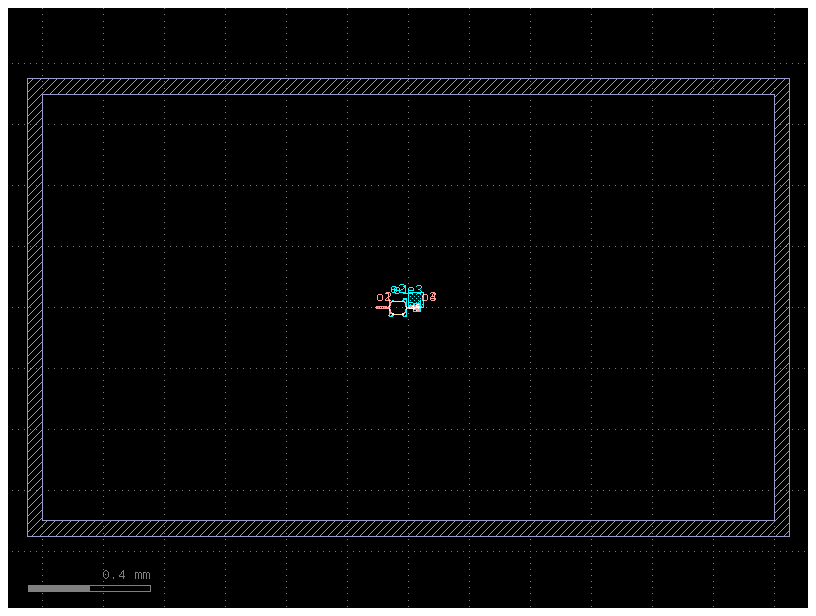

In [1]:
import gdsfactory as gf
import numpy as np
import Lab_PDK_DAVID as pdk
gf.gpdk.PDK.activate()

c = gf.Component()
mzi = c << pdk.MZI2(L = 10, w = 0.5, layer=(1, 0))
gc = c << gf.components.grating_coupler_elliptical_te()
pad = c << gf.c.rectangle(size=(50,50), layer=(2,0))
die = c << pdk.die_with_trenches(size = (2500, 1500))
c.add_ports(mzi.ports)
c.draw_ports()
c.plot()
directory = r'C:\Users\david\Desktop\PIC-CHERTE\PROGRAMMING\Lab_design2'
c.write_gds(directory+"/test_gds.gds",with_metadata=False)
c.show()

C:\Users\david\AppData\Roaming\Python\Python313\site-packages\cachetools\_cached.py:185: UserWarning: bend_euler angle should be 90 or 180. Got -60. Use bend_euler_all_angle instead.
  v = func(*args, **kwargs)
C:\Users\david\AppData\Roaming\Python\Python313\site-packages\cachetools\_cached.py:185: UserWarning: bend_euler angle should be 90 or 180. Got 60. Use bend_euler_all_angle instead.
  v = func(*args, **kwargs)


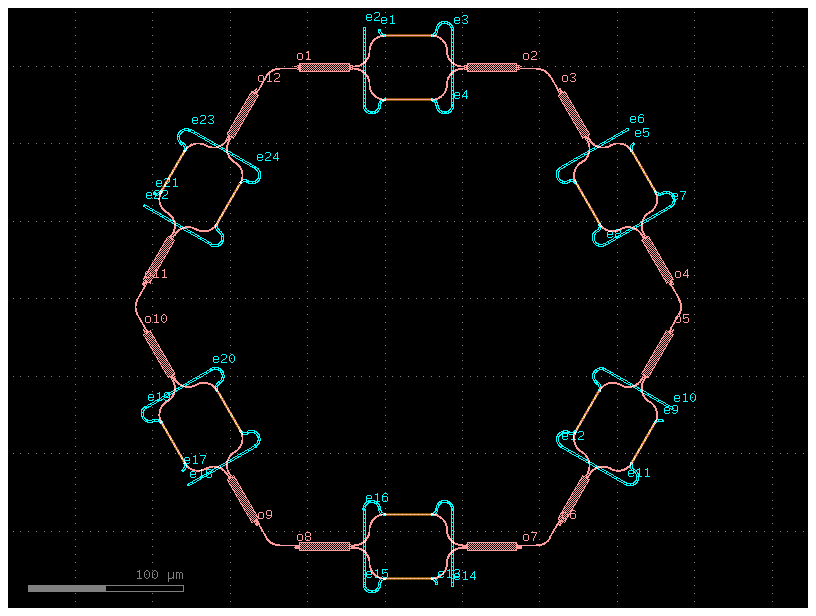

In [2]:
def hexagon_MZI(L = 10, w = 0.5, layer=(1, 0)):
    c = gf.Component()
    mzi1 = c << pdk.MZI2(L = 10, w = 0.5, layer=(1, 0))
    S1 = c << pdk.straight(L, width=.5)
    S1.connect(port="o1", other = mzi1.ports["o4"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False)
    B1 = c << gf.components.bend_circular(radius = 10, angle=-60,width=0.5)
    B1.connect(port="o1", other = S1.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False)
    S2 = c << pdk.straight(L, width=.5)
    S2.connect(port="o1", other = B1.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False)

    mzi2 = c << pdk.MZI2(L = 10, w = 0.5, layer=(1, 0))
    mzi2.connect(port="o2", other = S2.ports["o2"])
    S3 = c << pdk.straight(L, width=.5)
    S3.connect(port="o1", other = mzi2.ports["o4"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False)
    B2 = c << gf.components.bend_circular(radius = 10, angle=60,width=0.5)
    B2.connect(port="o1", other = S3.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = True)
    S4 = c << pdk.straight(L, width=.5)
    S4.connect(port="o1", other = B2.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False)

    mzi3 = c << pdk.MZI2(L = 10, w = 0.5, layer=(1, 0))
    mzi3.connect(port="o2", other = S4.ports["o2"])
    S5 = c << pdk.straight(L, width=.5)
    S5.connect(port="o1", other = mzi3.ports["o4"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False)
    B3 = c << gf.components.bend_circular(radius = 10, angle=60,width=0.5)
    B3.connect(port="o1", other = S5.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = True)
    S6 = c << pdk.straight(L, width=.5)
    S6.connect(port="o1", other = B3.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False)

    mzi4 = c << pdk.MZI2(L = 10, w = 0.5, layer=(1, 0))
    mzi4.connect(port="o2", other = S6.ports["o2"])
    S7 = c << pdk.straight(L, width=.5)
    S7.connect(port="o1", other = mzi4.ports["o4"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False)
    B4 = c << gf.components.bend_circular(radius = 10, angle=60,width=0.5)
    B4.connect(port="o1", other = S7.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = True)
    S8 = c << pdk.straight(L, width=.5)
    S8.connect(port="o1", other = B4.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False)

    mzi5 = c << pdk.MZI2(L = 10, w = 0.5, layer=(1, 0))
    mzi5.connect(port="o2", other = S8.ports["o2"])
    S9 = c << pdk.straight(L, width=.5)
    S9.connect(port="o1", other = mzi5.ports["o4"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False)
    B5 = c << gf.components.bend_circular(radius = 10, angle=60,width=0.5)
    B5.connect(port="o1", other = S9.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = True)
    S10 = c << pdk.straight(L, width=.5)
    S10.connect(port="o1", other = B5.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False)

    mzi6 = c << pdk.MZI2(L = 10, w = 0.5, layer=(1, 0))
    mzi6.connect(port="o2", other = S10.ports["o2"])
    S11 = c << pdk.straight(L, width=.5)
    S11.connect(port="o1", other = mzi6.ports["o4"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False)
    B6 = c << gf.components.bend_circular(radius = 10, angle=60,width=0.5)
    B6.connect(port="o1", other = S11.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = True)
    S12 = c << pdk.straight(L, width=.5)
    S12.connect(port="o1", other = B6.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False)

    #MZI1
    c.add_port("e4", port=mzi1.ports["e4"], port_type="electrical")
    c.add_port("e2", port=mzi1.ports["e2"], port_type="electrical")
    c.add_port("e1", port=mzi1.ports["e1"], port_type="electrical")
    c.add_port("e3", port=mzi1.ports["e3"], port_type="electrical")
    c.add_port("o2",port=mzi1.ports["o3"], port_type="optical")
    c.add_port("o1",port=mzi1.ports["o1"], port_type="optical")

    #MZI2
    c.add_port("e6", port=mzi2.ports["e2"], port_type="electrical")
    c.add_port("e8", port=mzi2.ports["e4"], port_type="electrical")
    c.add_port("e5", port=mzi2.ports["e1"], port_type="electrical")
    c.add_port("e7", port=mzi2.ports["e3"], port_type="electrical")
    c.add_port("o4",port=mzi2.ports["o3"], port_type="optical")
    c.add_port("o3",port=mzi2.ports["o1"], port_type="optical")

    #MZI3
    c.add_port("e10", port=mzi3.ports["e2"], port_type="electrical")
    c.add_port("e12", port=mzi3.ports["e4"], port_type="electrical")
    c.add_port("e9", port=mzi3.ports["e1"], port_type="electrical")
    c.add_port("e11", port=mzi3.ports["e3"], port_type="electrical")
    c.add_port("o6",port=mzi3.ports["o3"], port_type="optical")
    c.add_port("o5",port=mzi3.ports["o1"], port_type="optical")

    #MZI4
    c.add_port("e14", port=mzi4.ports["e2"], port_type="electrical")
    c.add_port("e16", port=mzi4.ports["e4"], port_type="electrical")
    c.add_port("e13", port=mzi4.ports["e1"], port_type="electrical")
    c.add_port("e15", port=mzi4.ports["e3"], port_type="electrical")
    c.add_port("o8",port=mzi4.ports["o3"], port_type="optical")
    c.add_port("o7",port=mzi4.ports["o1"], port_type="optical")

    #MZI5
    c.add_port("e18", port=mzi5.ports["e2"], port_type="electrical")
    c.add_port("e20", port=mzi5.ports["e4"], port_type="electrical")
    c.add_port("e17", port=mzi5.ports["e1"], port_type="electrical")
    c.add_port("e19", port=mzi5.ports["e3"], port_type="electrical")
    c.add_port("o10",port=mzi5.ports["o3"], port_type="optical")
    c.add_port("o9",port=mzi5.ports["o1"], port_type="optical")

    #MZI6
    c.add_port("e22", port=mzi6.ports["e2"], port_type="electrical")
    c.add_port("e24", port=mzi6.ports["e4"], port_type="electrical")
    c.add_port("e21", port=mzi6.ports["e1"], port_type="electrical")
    c.add_port("e23", port=mzi6.ports["e3"], port_type="electrical")
    c.add_port("o12",port=mzi6.ports["o3"], port_type="optical")
    c.add_port("o11",port=mzi6.ports["o1"], port_type="optical")
    
    return c

f = gf.Component()

ps = f << hexagon_MZI(L = 10, w = 0.5, layer=(1, 0))
f.add_ports(ps.ports)
f.draw_ports()
f.plot()
f.show()
directory = r'C:\Users\david\Desktop\PIC-CHERTE\PROGRAMMING\Lab_design2'
f.write_gds(directory+"/test_gds.gds",with_metadata=False)
f.show()



C:\Users\david\AppData\Local\Temp\ipykernel_4816\143212134.py:58: DeprecationWarning: route_single is less flexible and will be removed in GDSFactory10. Please use route_bundle instead.
  gf.routing.route_single(c, S1.ports['o2'],c.ports['opt_right_5'],radius=10, layer=(1,0),route_width=0.5)
C:\Users\david\AppData\Local\Temp\ipykernel_4816\143212134.py:63: DeprecationWarning: route_single is less flexible and will be removed in GDSFactory10. Please use route_bundle instead.
  gf.routing.route_single(c, B3.ports['o2'],c.ports['opt_right_4'],radius=10, layer=(1,0),route_width=0.5)
C:\Users\david\AppData\Local\Temp\ipykernel_4816\143212134.py:68: DeprecationWarning: route_single is less flexible and will be removed in GDSFactory10. Please use route_bundle instead.
  gf.routing.route_single(c, B4.ports['o1'],c.ports['opt_right_3'],radius=10, layer=(1,0),route_width=0.5)
C:\Users\david\AppData\Local\Temp\ipykernel_4816\143212134.py:73: DeprecationWarning: route_single is less flexible and w

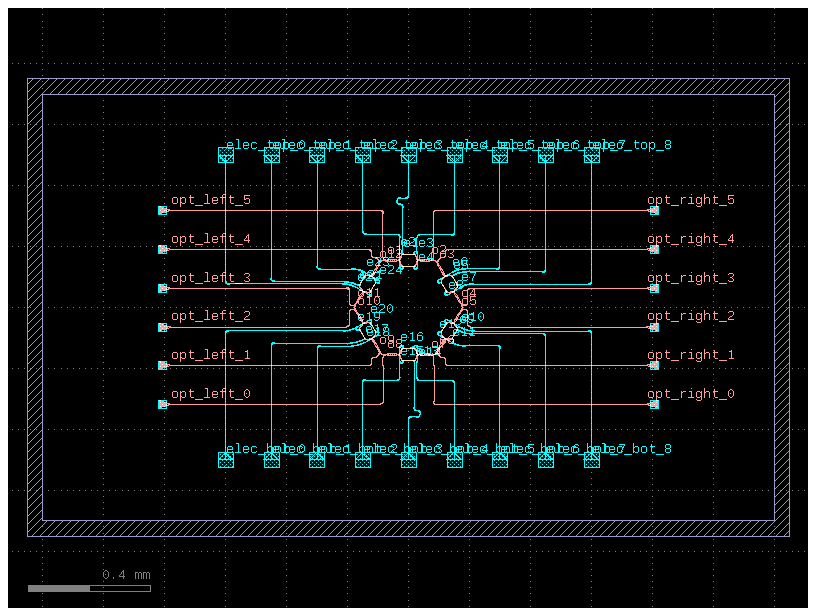

In [82]:
c = gf.Component(
)

# 1. MZI (Mantenemos tu bloque base)
mzi = c << hexagon_MZI(L=10, w=0.5, layer=(1, 0))
mzi.center = (0, 0)
c.add_ports(mzi.ports)

# --- CONFIGURACIÓN ---
n_pads = 9
pitch_pads = 150
n_gcs = 6
pitch_gcs = 127

# 2. Pads Eléctricos (9 arriba y 9 abajo)
# El rango se calcula para que queden centrados en x=0
start_pad = -(n_pads - 1) * pitch_pads / 2

for i in range(n_pads):
    x_pos = start_pad + (i * pitch_pads)
    
    # Pads Superiores
    pad_top = c << gf.components.rectangle(size=(50, 50), layer=(2, 0))
    pad_top.center = (x_pos, 500)
    c.add_port(name=f"elec_top_{i}", center=pad_top.center, width=50, orientation=-90, layer=(2, 0), port_type="electrical")
    
    # Pads Inferiores
    pad_bot = c << gf.components.rectangle(size=(50, 50), layer=(2, 0))
    pad_bot.center = (x_pos, -500)
    c.add_port(name=f"elec_bot_{i}", center=pad_bot.center, width=50, orientation=90, layer=(2, 0), port_type="electrical")

# 3. Grating Couplers (6 a cada lado)
# El rango se calcula para que queden centrados en y=0
start_gc = -(n_gcs - 1) * pitch_gcs / 2

for i in range(n_gcs):
    y_pos = start_gc + (i * pitch_gcs)
    
    # GCs Lado Derecho
    gc_right = c << gf.components.grating_coupler_elliptical_te()
    gc_right.center = (800, y_pos) # Ajustado el X para que no choque con los pads
    c.add_port(name=f"opt_right_{i}", port=gc_right.ports["o1"])
    
    # GCs Lado Izquierdo
    gc_left = c << gf.components.grating_coupler_elliptical_te()
    gc_left.drotate(180)
    gc_left.center = (-800, y_pos)
    c.add_port(name=f"opt_left_{i}", port=gc_left.ports["o1"])

# 4. Die (Ajustado el tamaño para que quepa todo el arreglo)
die = c << pdk.die_with_trenches(size=(2500, 1500))

#o2
S1 = c << pdk.straight(25, width=0.5)
B1 = c << gf.components.bend_circular(radius = 10, angle=90,width=0.5)
B1.connect(port="o1", other = mzi.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False)
S1.connect(port="o1", other = B1.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False)
gf.routing.route_single(c, S1.ports['o2'],c.ports['opt_right_5'],radius=10, layer=(1,0),route_width=0.5)

#o3
B3 = c << gf.components.bend_circular(radius = 15, angle=-120,width=0.5)
B3.connect(port="o1", other = mzi.ports["o3"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False)
gf.routing.route_single(c, B3.ports['o2'],c.ports['opt_right_4'],radius=10, layer=(1,0),route_width=0.5)

#o4
B4 = c << gf.components.bend_circular(radius = 15, angle=-60,width=0.5)
B4.connect(port="o2", other = mzi.ports["o4"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False)
gf.routing.route_single(c, B4.ports['o1'],c.ports['opt_right_3'],radius=10, layer=(1,0),route_width=0.5)

#o5
B5 = c << gf.components.bend_circular(radius = 15, angle=-60,width=0.5)
B5.connect(port="o1", other = mzi.ports["o5"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False)
gf.routing.route_single(c, B5.ports['o2'],c.ports['opt_right_2'],radius=10, layer=(1,0),route_width=0.5)

#o6
B6 = c << gf.components.bend_circular(radius = 15, angle=120,width=0.5)
B6.connect(port="o1", other = mzi.ports["o6"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False)
gf.routing.route_single(c, B6.ports['o2'],c.ports['opt_right_1'],radius=10, layer=(1,0),route_width=0.5)

#o7
S2 = c << pdk.straight(25, width=0.5)
B7 = c << gf.components.bend_circular(radius = 10, angle=-90,width=0.5)
B7.connect(port="o1", other = mzi.ports["o7"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False)
S2.connect(port="o1", other = B7.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False)
gf.routing.route_single(c, S2.ports['o2'],c.ports['opt_right_0'],radius=10, layer=(1,0),route_width=0.5)

#o1
S3 = c << pdk.straight(25, width=0.5)
B8 = c << gf.components.bend_circular(radius = 10, angle=-90,width=0.5)
B8.connect(port="o1", other = mzi.ports["o1"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False)
S3.connect(port="o1", other = B8.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False)
gf.routing.route_single(c, S3.ports['o2'],c.ports['opt_left_5'],radius=10, layer=(1,0),route_width=0.5)

#o12
B9 = c << gf.components.bend_circular(radius = 15, angle=120,width=0.5)
B9.connect(port="o1", other = mzi.ports["o12"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False)
gf.routing.route_single(c, B9.ports['o2'],c.ports['opt_left_4'],radius=10, layer=(1,0),route_width=0.5)

#o11
B10 = c << gf.components.bend_circular(radius = 15, angle=60,width=0.5)
B10.connect(port="o2", other = mzi.ports["o11"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False)
gf.routing.route_single(c, B10.ports['o1'],c.ports['opt_left_3'],radius=10, layer=(1,0),route_width=0.5)

#o10
B11 = c << gf.components.bend_circular(radius = 15, angle=60,width=0.5)
B11.connect(port="o1", other = mzi.ports["o10"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False)
gf.routing.route_single(c, B11.ports['o2'],c.ports['opt_left_2'],radius=10, layer=(1,0),route_width=0.5)

#o9
B12 = c << gf.components.bend_circular(radius = 15, angle=-120,width=0.5)
B12.connect(port="o1", other = mzi.ports["o9"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False)
gf.routing.route_single(c, B12.ports['o2'],c.ports['opt_left_1'],radius=10, layer=(1,0),route_width=0.5)

#o8
S4 = c << pdk.straight(25, width=0.5)
B12 = c << gf.components.bend_circular(radius = 10, angle=90,width=0.5)
B12.connect(port="o1", other = mzi.ports["o8"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False)
S4.connect(port="o1", other = B12.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False)
gf.routing.route_single(c, S4.ports['o2'],c.ports['opt_left_0'],radius=10, layer=(1,0),route_width=0.5)

#e22
S22 = c << pdk.straight(14*25, width=1.25, layer=(2,0))
B22 = c << gf.components.bend_circular(radius = 90, angle=30,width=1.25, layer=(2,0))
B22.connect(port="o1", other = mzi.ports["e22"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False,allow_type_mismatch=True)
S22.connect(port="o1", other = B22.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False,allow_type_mismatch=True)
gf.routing.route_single(c, S22.ports['o2'],c.ports['elec_top_0'],radius=10, layer=(2,0),route_width=1.25,allow_width_mismatch=True)

#e21
S21 = c << pdk.straight(5*25, width=1.25, layer=(2,0))
B21 = c << gf.components.bend_circular(radius = 90, angle=30,width=1.25, layer=(2,0))
B21.connect(port="o1", other = mzi.ports["e21"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False,allow_type_mismatch=True)
S21.connect(port="o1", other = B21.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False,allow_type_mismatch=True)
gf.routing.route_single(c, S21.ports['o2'],c.ports['elec_top_1'],radius=10, layer=(2,0),route_width=1.25,allow_width_mismatch=True)

#e23
S23 = c << pdk.straight(2*25, width=1.25, layer=(2,0))
B23 = c << gf.components.bend_circular(radius = 90, angle=30,width=1.25, layer=(2,0))
B23.connect(port="o1", other = mzi.ports["e23"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False,allow_type_mismatch=True)
S23.connect(port="o1", other = B23.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False,allow_type_mismatch=True)
gf.routing.route_single(c, S23.ports['o2'],c.ports['elec_top_2'],radius=10, layer=(2,0),route_width=1.25,allow_width_mismatch=True)

#e2
Se2 = c << pdk.straight(2*25, width=1.25, layer=(2,0))
Se2.connect(port="o1", other = mzi.ports["e2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False,allow_type_mismatch=True)
gf.routing.route_single(c, Se2.ports['o2'],c.ports['elec_top_3'],radius=10, layer=(2,0),route_width=1.25,allow_width_mismatch=True)

#e1
Se1 = c << pdk.straight(6*25, width=1.25, layer=(2,0))
Se1.connect(port="o1", other = mzi.ports["e1"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False,allow_type_mismatch=True)
gf.routing.route_single(c, Se1.ports['o2'],c.ports['elec_top_4'],radius=10, layer=(2,0),route_width=1.25,allow_width_mismatch=True)

#e3
Se3 = c << pdk.straight(2*25, width=1.25, layer=(2,0))
Se3.connect(port="o1", other = mzi.ports["e3"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False,allow_type_mismatch=True)
gf.routing.route_single(c, Se3.ports['o2'],c.ports['elec_top_5'],radius=10, layer=(2,0),route_width=1.25,allow_width_mismatch=True)

#e6
Se6 = c << pdk.straight(2*25, width=1.25, layer=(2,0))
Be6 = c << gf.components.bend_circular(radius = 90, angle=-30,width=1.25, layer=(2,0))
Be6.connect(port="o1", other = mzi.ports["e6"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False,allow_type_mismatch=True)
Se6.connect(port="o1", other = Be6.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False,allow_type_mismatch=True)
gf.routing.route_single(c, Se6.ports['o2'],c.ports['elec_top_6'],radius=10, layer=(2,0),route_width=1.25,allow_width_mismatch=True)

#e5
Se5 = c << pdk.straight(2*25, width=1.25, layer=(2,0))
Be5 = c << gf.components.bend_circular(radius = 90, angle=-30,width=1.25, layer=(2,0))
Be5.connect(port="o1", other = mzi.ports["e5"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False,allow_type_mismatch=True)
Se5.connect(port="o1", other = Be5.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False,allow_type_mismatch=True)
gf.routing.route_single(c, Se5.ports['o2'],c.ports['elec_top_7'],radius=10, layer=(2,0),route_width=1.25,allow_width_mismatch=True)

#e7
Se7 = c << pdk.straight(14*25, width=1.25, layer=(2,0))
Be7 = c << gf.components.bend_circular(radius = 90, angle=-30,width=1.25, layer=(2,0))
Be7.connect(port="o1", other = mzi.ports["e7"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False,allow_type_mismatch=True)
Se7.connect(port="o1", other = Be7.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False,allow_type_mismatch=True)
gf.routing.route_single(c, Se7.ports['o2'],c.ports['elec_top_8'],radius=10, layer=(2,0),route_width=1.25,allow_width_mismatch=True)

#e19
S19 = c << pdk.straight(14*25, width=1.25, layer=(2,0))
B19 = c << gf.components.bend_circular(radius = 90, angle=-30,width=1.25, layer=(2,0))
B19.connect(port="o1", other = mzi.ports["e19"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False,allow_type_mismatch=True)
S19.connect(port="o1", other = B19.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False,allow_type_mismatch=True)
gf.routing.route_single(c, S19.ports['o2'],c.ports['elec_bot_0'],radius=10, layer=(2,0),route_width=1.25,allow_width_mismatch=True)

#e17
S17 = c << pdk.straight(2*25, width=1.25, layer=(2,0))
B17 = c << gf.components.bend_circular(radius = 90, angle=-30,width=1.25, layer=(2,0))
B17.connect(port="o1", other = mzi.ports["e17"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False,allow_type_mismatch=True)
S17.connect(port="o1", other = B17.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False,allow_type_mismatch=True)
gf.routing.route_single(c, S17.ports['o2'],c.ports['elec_bot_1'],radius=10, layer=(2,0),route_width=1.25,allow_width_mismatch=True)

#e18
S18 = c << pdk.straight(2*25, width=1.25, layer=(2,0))
B18 = c << gf.components.bend_circular(radius = 90, angle=-30,width=1.25, layer=(2,0))
B18.connect(port="o1", other = mzi.ports["e18"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False,allow_type_mismatch=True)
S18.connect(port="o1", other = B18.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False,allow_type_mismatch=True)
gf.routing.route_single(c, S18.ports['o2'],c.ports['elec_bot_2'],radius=10, layer=(2,0),route_width=1.25,allow_width_mismatch=True)

#e15
S15 = c << pdk.straight(2*25, width=1.25, layer=(2,0))
S15.connect(port="o1", other = mzi.ports["e15"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False,allow_type_mismatch=True)
gf.routing.route_single(c, S15.ports['o2'],c.ports['elec_bot_3'],radius=10, layer=(2,0),route_width=1.25,allow_width_mismatch=True)

#e13
S13 = c << pdk.straight(6*25, width=1.25, layer=(2,0))
S13.connect(port="o1", other = mzi.ports["e13"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False,allow_type_mismatch=True)
gf.routing.route_single(c, S13.ports['o2'],c.ports['elec_bot_4'],radius=10, layer=(2,0),route_width=1.25,allow_width_mismatch=True)

#e14
S14 = c << pdk.straight(2*25, width=1.25, layer=(2,0))
S14.connect(port="o1", other = mzi.ports["e14"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False,allow_type_mismatch=True)
gf.routing.route_single(c, S14.ports['o2'],c.ports['elec_bot_5'],radius=10, layer=(2,0),route_width=1.25,allow_width_mismatch=True)

#e11
Se11 = c << pdk.straight(2*25, width=1.25, layer=(2,0))
Be11 = c << gf.components.bend_circular(radius = 90, angle=30,width=1.25, layer=(2,0))
Be11.connect(port="o1", other = mzi.ports["e11"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False,allow_type_mismatch=True)
Se11.connect(port="o1", other = Be11.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False,allow_type_mismatch=True)
gf.routing.route_single(c, Se11.ports['o2'],c.ports['elec_bot_6'],radius=10, layer=(2,0),route_width=1.25,allow_width_mismatch=True)

#e10
Se10 = c << pdk.straight(14*25, width=1.25, layer=(2,0))
Be10 = c << gf.components.bend_circular(radius = 90, angle=30,width=1.25, layer=(2,0))
Be10.connect(port="o1", other = mzi.ports["e10"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False,allow_type_mismatch=True)
Se10.connect(port="o1", other = Be10.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False,allow_type_mismatch=True)
gf.routing.route_single(c, Se10.ports['o2'],c.ports['elec_bot_8'],radius=10, layer=(2,0),route_width=1.25,allow_width_mismatch=True)

#e9
Se9 = c << pdk.straight(2*25, width=1.25, layer=(2,0))
Be9 = c << gf.components.bend_circular(radius = 90, angle=30,width=1.25, layer=(2,0))
Be9.connect(port="o1", other = mzi.ports["e9"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False,allow_type_mismatch=True)
Se9.connect(port="o1", other = Be9.ports["o2"], allow_width_mismatch=True, allow_layer_mismatch = True, mirror = False,allow_type_mismatch=True)
gf.routing.route_single(c, Se9.ports['o2'],c.ports['elec_bot_7'],radius=10, layer=(2,0),route_width=1.25,allow_width_mismatch=True)


c.add_ports(mzi.ports)
c.draw_ports()
c.plot()
directory = r'C:\Users\david\Desktop\PIC-CHERTE\PROGRAMMING\Lab_design2'
c.write_gds(directory+"/test_gds.gds",with_metadata=False)
c.show()